In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
FILE_NAME = "Siemens_Energy_Clustering Dataset.csv"

In [ ]:
df = pd.read_csv(FILE_NAME)

In [ ]:
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 321
Number of columns: 158


In [ ]:
display(df.head())

,series_id,start_timestamp,Week_1,Week_2,Week_3,Week_4,Week_5,Week_6,Week_7,Week_8,...,Week_147,Week_148,Week_149,Week_150,Week_151,Week_152,Week_153,Week_154,Week_155,Week_156
0,T1,2012-01-01 00-00-00,8032.0,9097.0,9394.0,8845.0,5619.0,3423.0,7764.0,10619.0,...,1319.0,1281.0,1542.0,1744.0,1697.0,1848.0,1682.0,1761.0,1760.0,1667.0
1,T2,2012-01-01 00-00-00,18707.0,18116.0,17821.0,18191.0,17957.0,18227.0,18612.0,18885.0,...,17944.0,16862.0,15980.0,15822.0,16172.0,15958.0,15906.0,15784.0,15573.0,15688.0
2,T3,2012-01-01 00-00-00,11220.0,15239.0,9753.0,20274.0,29283.0,36683.0,38309.0,37423.0,...,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1133.0
3,T4,2012-01-01 00-00-00,83369.0,81878.0,83173.0,80482.0,86231.0,91704.0,89284.0,77948.0,...,73702.0,73923.0,80014.0,85674.0,87184.0,86563.0,88779.0,94601.0,98122.0,99051.0
4,T5,2012-01-01 00-00-00,43956.0,44750.0,44668.0,43102.0,44661.0,46139.0,44406.0,39863.0,...,29136.0,27988.0,37364.0,40651.0,39993.0,40655.0,42235.0,47131.0,48459.0,49855.0


In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['series_id', 'start_timestamp', 'Week_1', 'Week_2', 'Week_3', 'Week_4', 'Week_5', 'Week_6', 'Week_7', 'Week_8', 'Week_9', 'Week_10', 'Week_11', 'Week_12', 'Week_13', 'Week_14', 'Week_15', 'Week_16', 'Week_17', 'Week_18', 'Week_19', 'Week_20', 'Week_21', 'Week_22', 'Week_23', 'Week_24', 'Week_25', 'Week_26', 'Week_27', 'Week_28', 'Week_29', 'Week_30', 'Week_31', 'Week_32', 'Week_33', 'Week_34', 'Week_35', 'Week_36', 'Week_37', 'Week_38', 'Week_39', 'Week_40', 'Week_41', 'Week_42', 'Week_43', 'Week_44', 'Week_45', 'Week_46', 'Week_47', 'Week_48', 'Week_49', 'Week_50', 'Week_51', 'Week_52', 'Week_53', 'Week_54', 'Week_55', 'Week_56', 'Week_57', 'Week_58', 'Week_59', 'Week_60', 'Week_61', 'Week_62', 'Week_63', 'Week_64', 'Week_65', 'Week_66', 'Week_67', 'Week_68', 'Week_69', 'Week_70', 'Week_71', 'Week_72', 'Week_73', 'Week_74', 'Week_75', 'Week_76', 'Week_77', 'Week_78', 'Week_79', 'Week_80', 'Week_81', 'Week_82', 'Week_83', 'Week_84', 'Week_85', 'Week_86', 'Week_87', 'Week

In [ ]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Columns: 158 entries, series_id to Week_156
dtypes: float64(156), object(2)
memory usage: 396.4+ KB


In [ ]:
print("\nMissing values:")
print(df.isnull().sum().sum())


Missing values:
0


In [ ]:
print("\nDuplicate rows:")
print(df.duplicated().sum())


Duplicate rows:
0


In [ ]:
print("\nStatistical summary:")
display(df.describe())


Statistical summary:


,Week_1,Week_2,Week_3,Week_4,Week_5,Week_6,Week_7,Week_8,Week_9,Week_10,...,Week_147,Week_148,Week_149,Week_150,Week_151,Week_152,Week_153,Week_154,Week_155,Week_156
count,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,...,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02
mean,3.807841e+05,3.928468e+05,3.931128e+05,3.903744e+05,3.859481e+05,3.863442e+05,3.831020e+05,3.832261e+05,3.876114e+05,3.909598e+05,...,4.629758e+05,4.299405e+05,3.796415e+05,3.739585e+05,3.755641e+05,3.651613e+05,3.582935e+05,3.587017e+05,3.647466e+05,3.432597e+05
std,1.583786e+06,1.627582e+06,1.624384e+06,1.625334e+06,1.594056e+06,1.575978e+06,1.576524e+06,1.590602e+06,1.621031e+06,1.666175e+06,...,2.440444e+06,2.103364e+06,1.660165e+06,1.603624e+06,1.608653e+06,1.536303e+06,1.473063e+06,1.459956e+06,1.473025e+06,1.408283e+06
min,1.530000e+03,1.545000e+03,1.513000e+03,1.487000e+03,1.507000e+03,1.513000e+03,1.444000e+03,1.542000e+03,1.542000e+03,1.552000e+03,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.139500e+04,5.407800e+04,5.439900e+04,5.393700e+04,5.439600e+04,5.501200e+04,5.304300e+04,4.886000e+04,4.861700e+04,4.765400e+04,...,4.704200e+04,4.619200e+04,4.599200e+04,4.764600e+04,4.723200e+04,4.515000e+04,4.601900e+04,4.922100e+04,4.920200e+04,4.689400e+04
50%,9.712700e+04,1.022770e+05,1.035030e+05,1.023730e+05,1.029510e+05,1.026090e+05,1.018540e+05,1.004890e+05,1.018110e+05,9.614600e+04,...,1.022690e+05,9.778200e+04,9.286800e+04,9.102600e+04,9.256900e+04,9.063800e+04,8.877900e+04,9.057300e+04,9.442700e+04,8.742800e+04
75%,2.388240e+05,2.450560e+05,2.466640e+05,2.486360e+05,2.493410e+05,2.482740e+05,2.420600e+05,2.351880e+05,2.396140e+05,2.416590e+05,...,2.520400e+05,2.441120e+05,2.225870e+05,2.195950e+05,2.196440e+05,2.266540e+05,2.224370e+05,2.244060e+05,2.275590e+05,2.152600e+05
max,2.357080e+07,2.405670e+07,2.393950e+07,2.393780e+07,2.347960e+07,2.304180e+07,2.317850e+07,2.314520e+07,2.370190e+07,2.474300e+07,...,4.009820e+07,3.378740e+07,2.550220e+07,2.429770e+07,2.430380e+07,2.314810e+07,2.179190e+07,2.146230e+07,2.162370e+07,2.094150e+07


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
week_columns = [
    col for col in df.columns
    if col.startswith("Week_")
]

In [ ]:
week_columns = sorted(
    week_columns,
    key=lambda col: int(col.split("_")[1])
)

In [ ]:
energy_df = df[
    ["series_id", "start_timestamp"] + week_columns
].copy()

In [ ]:
energy_df[week_columns] = energy_df[week_columns].apply(
    pd.to_numeric, errors="coerce"
)

In [ ]:
energy_df[week_columns] = energy_df[week_columns].replace(
    [np.inf, -np.inf], np.nan
)

In [ ]:
energy_df[week_columns] = energy_df[week_columns].fillna(
    energy_df[week_columns].median()
)

In [ ]:
energy_df = energy_df.dropna(subset=week_columns)

In [ ]:
energy_df = energy_df.drop_duplicates(subset="series_id")


In [ ]:
energy_df = energy_df.reset_index(drop=True)

In [ ]:
print("Data processing completed!")
print("Number of series:", len(energy_df))
print("Number of weekly features:", len(week_columns))

Data processing completed!
Number of series: 321
Number of weekly features: 156


In [ ]:
display(energy_df.head())

,series_id,start_timestamp,Week_1,Week_2,Week_3,Week_4,Week_5,Week_6,Week_7,Week_8,...,Week_147,Week_148,Week_149,Week_150,Week_151,Week_152,Week_153,Week_154,Week_155,Week_156
0,T1,2012-01-01 00-00-00,8032.0,9097.0,9394.0,8845.0,5619.0,3423.0,7764.0,10619.0,...,1319.0,1281.0,1542.0,1744.0,1697.0,1848.0,1682.0,1761.0,1760.0,1667.0
1,T2,2012-01-01 00-00-00,18707.0,18116.0,17821.0,18191.0,17957.0,18227.0,18612.0,18885.0,...,17944.0,16862.0,15980.0,15822.0,16172.0,15958.0,15906.0,15784.0,15573.0,15688.0
2,T3,2012-01-01 00-00-00,11220.0,15239.0,9753.0,20274.0,29283.0,36683.0,38309.0,37423.0,...,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1324.0,1133.0
3,T4,2012-01-01 00-00-00,83369.0,81878.0,83173.0,80482.0,86231.0,91704.0,89284.0,77948.0,...,73702.0,73923.0,80014.0,85674.0,87184.0,86563.0,88779.0,94601.0,98122.0,99051.0
4,T5,2012-01-01 00-00-00,43956.0,44750.0,44668.0,43102.0,44661.0,46139.0,44406.0,39863.0,...,29136.0,27988.0,37364.0,40651.0,39993.0,40655.0,42235.0,47131.0,48459.0,49855.0


In [ ]:
summary_df = pd.DataFrame()

In [ ]:
summary_df["series_id"] = energy_df["series_id"]
summary_df["Average_Consumption"] = energy_df[week_columns].mean(axis=1)
summary_df["Minimum_Consumption"] = energy_df[week_columns].min(axis=1)
summary_df["Maximum_Consumption"] = energy_df[week_columns].max(axis=1)
summary_df["Total_Consumption"] = energy_df[week_columns].sum(axis=1)
summary_df["Standard_Deviation"] = energy_df[week_columns].std(axis=1)

In [ ]:
print("Energy consumption summary:")
display(summary_df.head())


Energy consumption summary:


,series_id,Average_Consumption,Minimum_Consumption,Maximum_Consumption,Total_Consumption,Standard_Deviation
0,T1,3915.467949,1048.0,11701.0,610813.0,3228.176072
1,T2,18976.294872,12026.0,24802.0,2960302.0,2307.656237
2,T3,2831.634615,1133.0,38309.0,441735.0,5785.106467
3,T4,73882.743590,57749.0,102885.0,11525708.0,11134.561073
4,T5,33631.660256,20236.0,49855.0,5246539.0,7851.926604


In [ ]:
print("\nOverall statistics:")
display(summary_df.describe())


Overall statistics:


,Average_Consumption,Minimum_Consumption,Maximum_Consumption,Total_Consumption,Standard_Deviation
count,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02,3.210000e+02
mean,4.267782e+05,3.073935e+05,6.229943e+05,6.657740e+07,8.022531e+04
std,2.099006e+06,1.299285e+06,3.720682e+06,3.274449e+08,7.077732e+05
min,1.791942e+03,0.000000e+00,6.284000e+03,2.795430e+05,5.479701e+02
25%,4.839036e+04,3.026400e+04,6.637800e+04,7.548896e+06,5.908404e+03
50%,9.945272e+04,7.463800e+04,1.276330e+05,1.551462e+07,1.248255e+04
75%,2.396214e+05,1.965700e+05,3.236380e+05,3.738093e+07,3.363599e+04
max,3.373515e+07,1.878860e+07,6.307530e+07,5.262684e+09,1.253968e+07


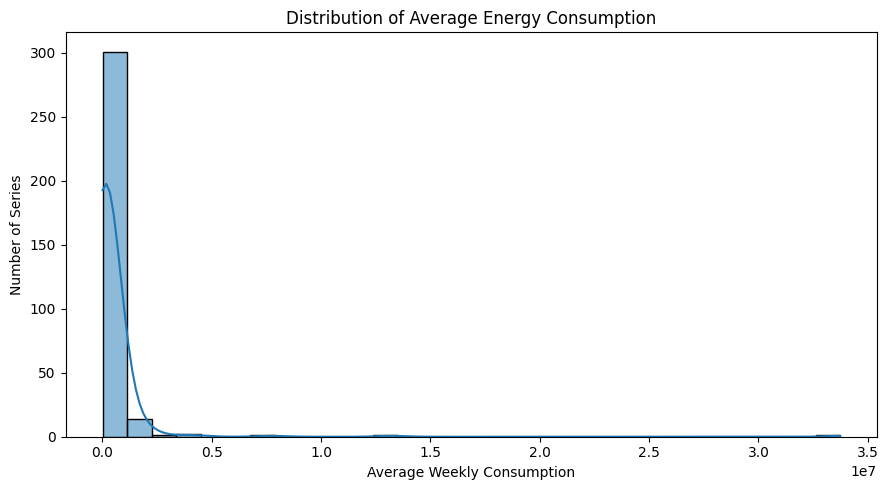

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    summary_df["Average_Consumption"],
    bins=30,
    kde=True
)

plt.title("Distribution of Average Energy Consumption")
plt.xlabel("Average Weekly Consumption")
plt.ylabel("Number of Series")
plt.tight_layout()
plt.show()

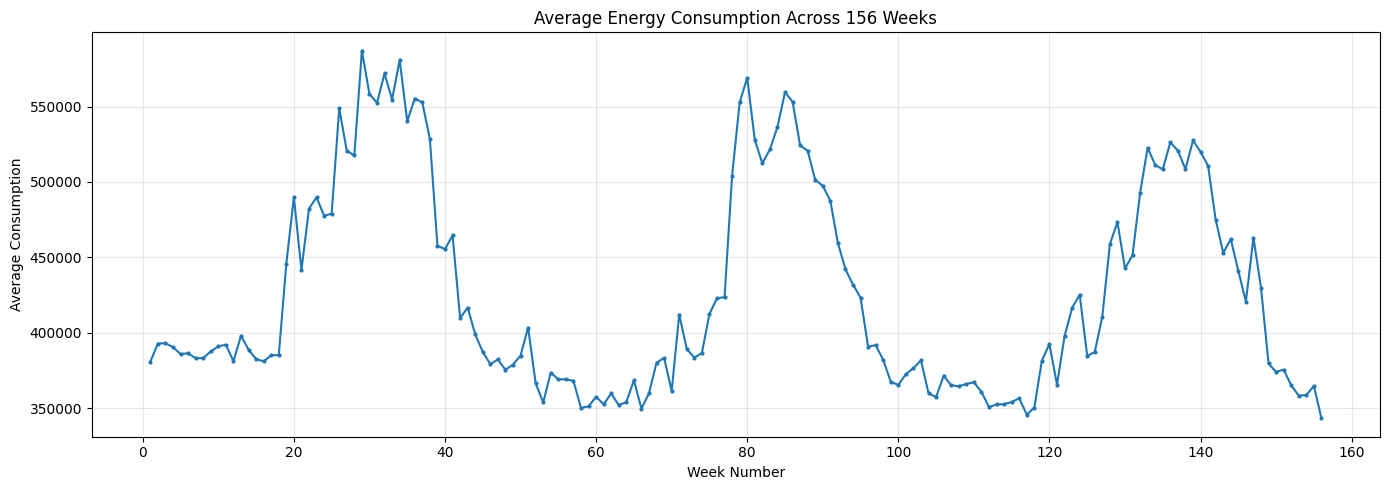

In [ ]:
weekly_average = energy_df[week_columns].mean(axis=0)

plt.figure(figsize=(14, 5))

plt.plot(
    range(1, len(week_columns) + 1),
    weekly_average.values,
    marker=".",
    markersize=4
)

plt.title("Average Energy Consumption Across 156 Weeks")
plt.xlabel("Week Number")
plt.ylabel("Average Consumption")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

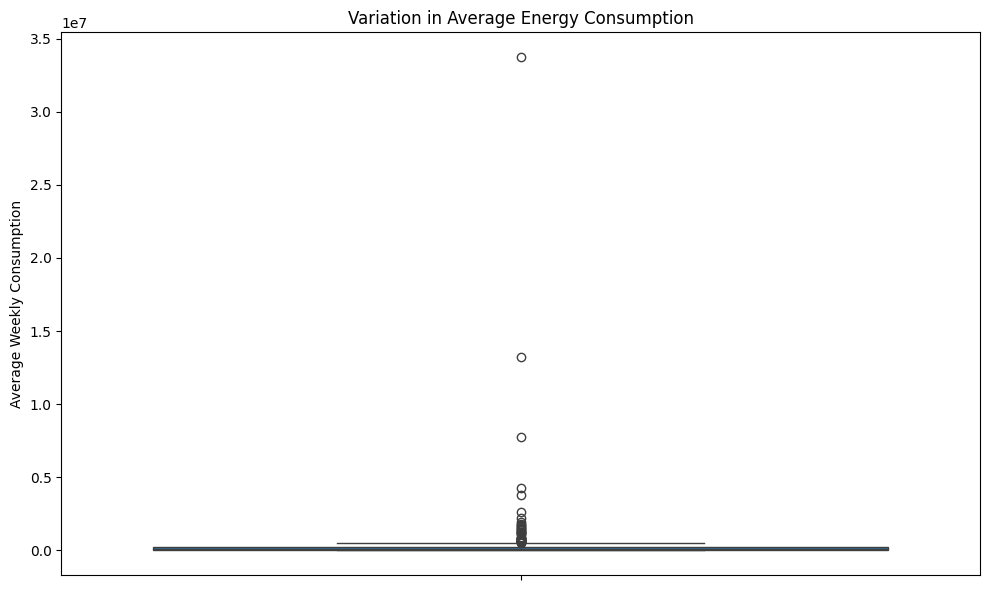

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=summary_df,
    y="Average_Consumption"
)

plt.title("Variation in Average Energy Consumption")
plt.ylabel("Average Weekly Consumption")
plt.tight_layout()
plt.show()

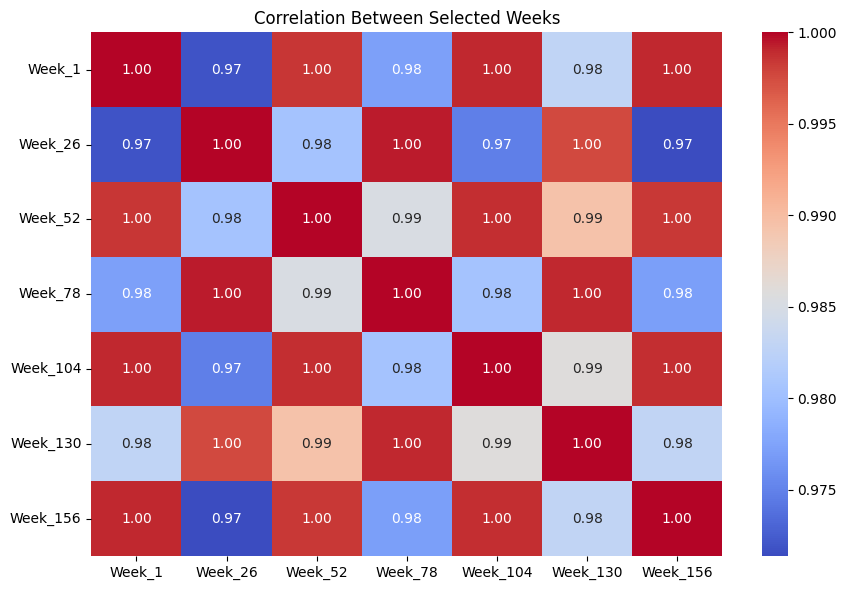

In [ ]:
selected_weeks = [
    "Week_1", "Week_26", "Week_52",
    "Week_78", "Week_104", "Week_130", "Week_156"
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    energy_df[selected_weeks].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Selected Weeks")
plt.tight_layout()
plt.show()

In [ ]:
X = energy_df[week_columns].copy()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
print("Model data prepared successfully!")
print("Number of series:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])

Model data prepared successfully!
Number of series: 321
Number of features: 156


In [ ]:
pca = PCA(n_components=2)

In [ ]:
X_pca = pca.fit_transform(X_scaled)

In [ ]:
print("PCA completed successfully!")

PCA completed successfully!


In [ ]:
print(
    "Variance explained by PC1 and PC2:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Variance explained by PC1 and PC2: 99.94 %


In [ ]:
print(
    "PC1 variance:",
    round(pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)

PC1 variance: 98.81 %


In [ ]:
print(
    "PC2 variance:",
    round(pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)

PC2 variance: 1.13 %


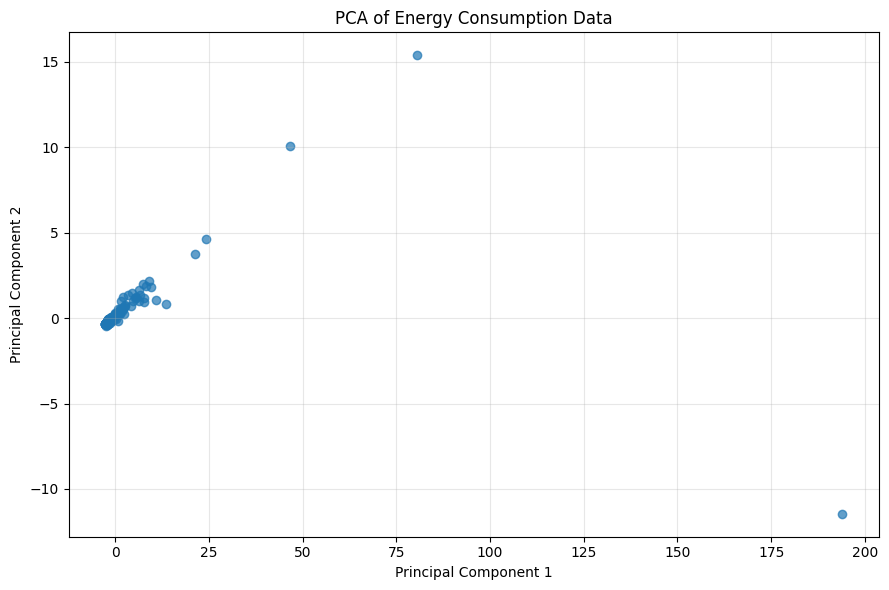

In [ ]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

plt.figure(figsize=(9, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.7
)

plt.title("PCA of Energy Consumption Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

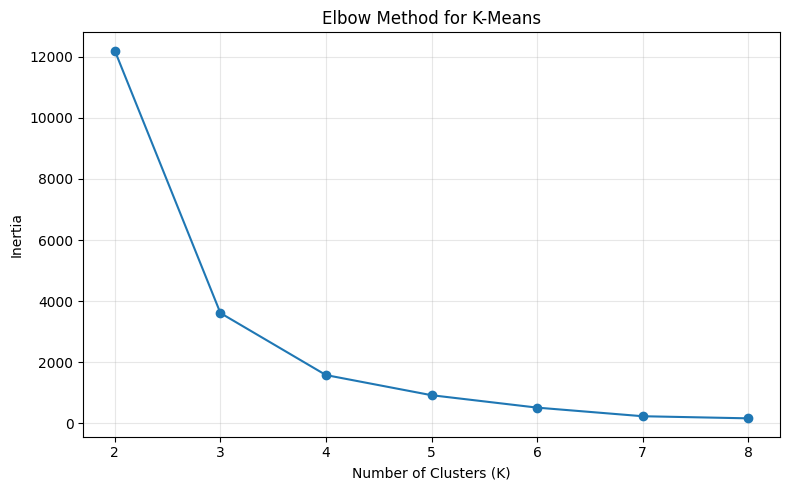

In [ ]:
inertia_values = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

For a simple starting model, we will use three clusters. You can change K = 3 if the elbow plot suggests another value.

In [ ]:
K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

# Train the model and assign each series to a cluster
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the data
results_df = energy_df[
    ["series_id", "start_timestamp"]
].copy()

results_df["Cluster"] = cluster_labels

print("K-Means model trained successfully!")
print("\nNumber of series in each cluster:")

print(
    results_df["Cluster"]
    .value_counts()
    .sort_index()
)

display(results_df.head(10))

K-Means model trained successfully!

Number of series in each cluster:
Cluster
0    318
1      1
2      2
Name: count, dtype: int64


,series_id,start_timestamp,Cluster
0,T1,2012-01-01 00-00-00,0
1,T2,2012-01-01 00-00-00,0
2,T3,2012-01-01 00-00-00,0
3,T4,2012-01-01 00-00-00,0
4,T5,2012-01-01 00-00-00,0
5,T6,2012-01-01 00-00-00,0
6,T7,2012-01-01 00-00-00,0
7,T8,2012-01-01 00-00-00,0
8,T9,2012-01-01 00-00-00,0
9,T10,2012-01-01 00-00-00,0


This is one of the most important graphs for your project because it combines the PCA visualization with the K-Means results.

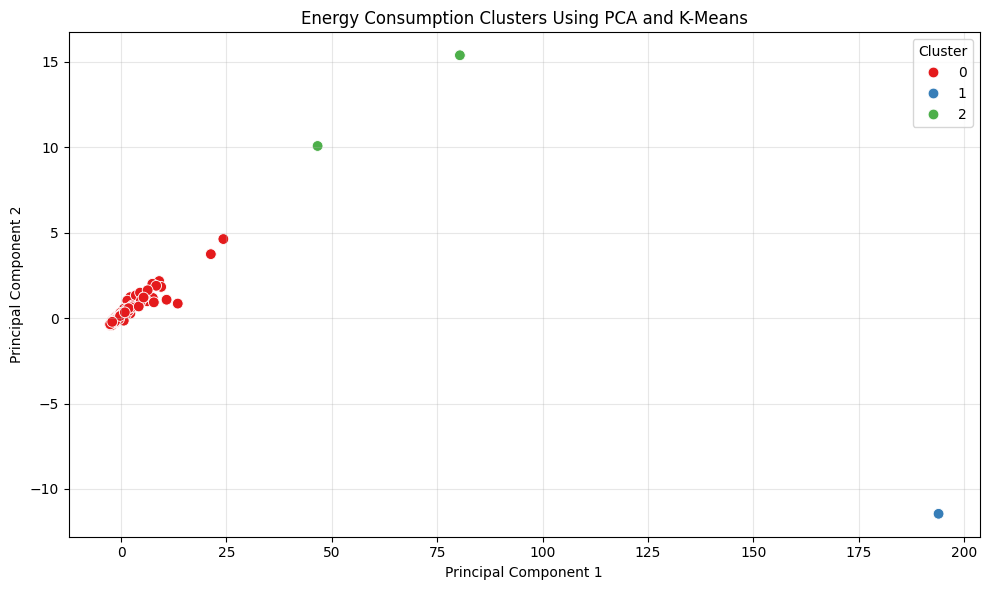

In [ ]:
# Add PCA coordinates to the results
results_df["PC1"] = X_pca[:, 0]
results_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=results_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=60
)

plt.title("Energy Consumption Clusters Using PCA and K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

We will calculate the silhouette score to measure how well the clusters are separated.

In [ ]:
silhouette = silhouette_score(X_scaled, cluster_labels)

print("Silhouette Score:", round(silhouette, 4))

if silhouette > 0.5:
    print("Interpretation: The clusters are relatively well separated.")
elif silhouette > 0.25:
    print("Interpretation: The clustering shows some useful structure.")
else:
    print("Interpretation: The clusters overlap or are not strongly separated.")

Silhouette Score: 0.9574
Interpretation: The clusters are relatively well separated.


Compare energy consumption across clusters

In [ ]:
# Combine cluster labels with consumption statistics
cluster_summary = summary_df.copy()

cluster_summary["Cluster"] = cluster_labels

cluster_profile = cluster_summary.groupby("Cluster")[
    [
        "Average_Consumption",
        "Minimum_Consumption",
        "Maximum_Consumption",
        "Total_Consumption",
        "Standard_Deviation"
    ]
].mean().round(2)

print("Average consumption profile for each cluster:")
display(cluster_profile)

Average consumption profile for each cluster:


,Average_Consumption,Minimum_Consumption,Maximum_Consumption,Total_Consumption,Standard_Deviation
Cluster,,,,,
0,258722.53,196898.16,345435.17,4.036071e+07,34332.04
1,33735152.56,18788600.00,63075300.00,5.262684e+09,12539683.13
2,10493442.70,8635546.50,13528741.50,1.636977e+09,1147525.76


Plot average consumption by cluster

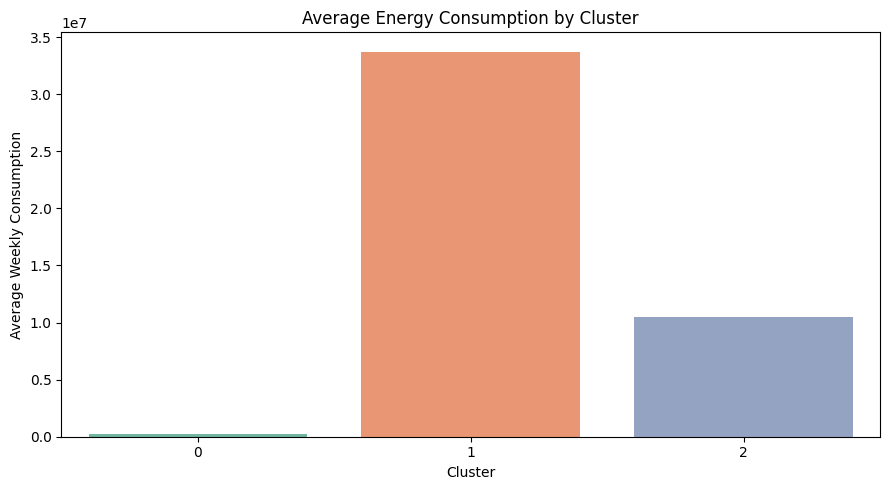

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_summary,
    x="Cluster",
    y="Average_Consumption",
    hue="Cluster",
    palette="Set2",
    errorbar=None,
    legend=False
)

plt.title("Average Energy Consumption by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Weekly Consumption")
plt.tight_layout()
plt.show()

In [ ]:
# Save the final clustering results
results_df.to_csv(
    "Siemens_Energy_Clustering_Results.csv",
    index=False
)

# Save the cluster summary
cluster_profile.to_csv(
    "Siemens_Energy_Cluster_Summary.csv"
)

print("Both result files have been saved!")

Both result files have been saved!


In [ ]:
from google.colab import files

files.download("Siemens_Energy_Clustering_Results.csv")
files.download("Siemens_Energy_Cluster_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>